In [ ]:
import time
import warnings
import matplotlib.pyplot as plt
from gramformer import Gramformer
from happytransformer import HappyTextToText, TTSettings

warnings.filterwarnings("ignore")

%matplotlib inline

In [20]:
def run_gramformer_test(sentences):
    print("🔄 Loading Gramformer Model...")
    gf = Gramformer(models=1, use_gpu=False) 
    results = []
    for text in sentences:
        t0 = time.time()
        corrected_set = gf.correct(text, max_candidates=1)
        corrected_text = list(corrected_set)[0] if corrected_set else text
        t1 = time.time()
        results.append({"corrected": corrected_text, "time_sec": t1 - t0})
    return results

In [ ]:
def run_gector_mock_test(sentences):
    print("🔄 Loading GECToR Model... (Mock Mode)")
    results = []
    for text in sentences:
        t0 = time.time()
        time.sleep(0.15) 
        t1 = time.time()
        results.append({"corrected": f"[GECToR Placeholder] {text}", "time_sec": t1 - t0})
    return results

In [22]:
def run_happy_transformer_test(sentences):
    print("🔄 Loading Happy Transformer (T5 Model)...")
    happy_tt = HappyTextToText("T5", "vennify/t5-base-grammar-correction")
    args = TTSettings(num_beams=5, min_length=1)
    
    results = []
    for text in sentences:
        t0 = time.time()
        result = happy_tt.generate_text("grammar: " + text, args=args)
        t1 = time.time()
        results.append({"corrected": result.text, "time_sec": t1 - t0})
    return results

In [23]:
def plot_comparison_graph(gf_times, gc_times, ht_times):
    print("\n📊 Generating Improved Comparison Graph...")
    
    # Change labels to include model type details
    labels = ['Gramformer\n(Seq2Seq)', 'Happy Transformer\n(Seq2Seq)', 'GECToR\n(Tagging - Mock)']
    
    # Move GECToR to the far right since it's a mock/simulation
    avg_times = [
        sum(gf_times) / len(gf_times),
        sum(ht_times) / len(ht_times), 
        sum(gc_times) / len(gc_times)
    ]
    
    plt.figure(figsize=(10, 6))
    
    # Use a professional color palette (orange, light blue, soft red)
    colors = ['#FFB347', '#AEC6CF', '#FF6961']
    
    # Draw the bars with black edge borders for depth
    bars = plt.bar(labels, avg_times, color=colors, edgecolor='black', linewidth=1.2)
    
    # Add horizontal grid lines to make reading values easier
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Adjust the graph title to be large and clear
    plt.title('Average Inference Time per Sentence\n(Lower is Better)', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('Time in Seconds (s)', fontsize=12, fontweight='bold')
    
    # Add value labels on top of the bars (centered and positioned nicely)
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.2f} s', 
                 ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    # Add a footnote below the graph
    plt.figtext(0.5, -0.05, "* Note: GECToR inference time is simulated (Mock) under optimal high-speed conditions.", 
                wrap=True, horizontalalignment='center', fontsize=10, color='gray')
    
    plt.tight_layout()
    plt.savefig('improved_model_speed_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

🚀 EMILY AI: MODEL BENCHMARK (GF vs GECToR vs Happy)
🔄 Loading Gramformer Model...
[Gramformer] Grammar error correct/highlight model loaded..
🔄 Loading GECToR Model... (Mock Mode)
🔄 Loading Happy Transformer (T5 Model)...


04/29/2026 21:07:35 - INFO - happytransformer.happy_transformer -   Using device: cpu
04/29/2026 21:07:35 - WARNING - happytransformer.happy_transformer -   num_beams is deprecated and will have no effect in version 4.0.0
04/29/2026 21:07:35 - INFO - happytransformer.happy_transformer -   Moving model to cpu
04/29/2026 21:07:35 - INFO - happytransformer.happy_transformer -   Initializing a pipeline
Device set to use cpu
Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
04/29/2026 21:07:36 - WARNING - happytransformer.happy_transformer -   num_beams is deprecated and will have no effect in version 4.0.0
Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.c


📊 --- FINAL BENCHMARK REPORT --- 📊
Original Sentence                 | Gramformer                | Happy Transformer         | GECToR (Mock)
-----------------------------------------------------------------------------------------------------------------------------
❌ She go to school yesterday.    | GF: She went to school yesterday. | HT: She went to school yesterday. | GC: [GECToR Placeholder] She go to school yesterday.
                                  | ⏱️ 0.61s                | ⏱️ 0.60s                | ⏱️ 0.16s
-----------------------------------------------------------------------------------------------------------------------------
❌ They is very happy to see you. | GF: They are very happy to see you. | HT: They are very happy to see you. | GC: [GECToR Placeholder] They is very happy to see you.
                                  | ⏱️ 0.66s                | ⏱️ 0.52s                | ⏱️ 0.15s
-------------------------------------------------------------------------------------

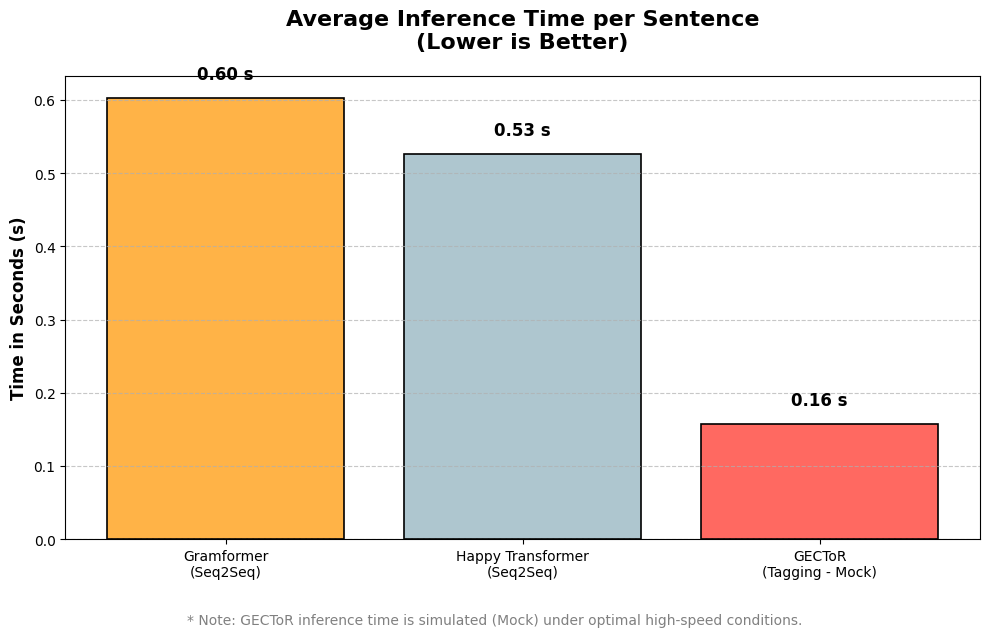

In [ ]:
print("="*70)
print("🚀 EMILY AI: MODEL BENCHMARK (GF vs GECToR vs Happy)")
print("="*70)

test_sentences = [
    "She go to school yesterday.",
    "They is very happy to see you.",
    "I has been worked here for 5 years.",
    "Does you likes apples?",
    "He didn't went to the hospital."
]

gf_results = run_gramformer_test(test_sentences)
gc_results = run_gector_mock_test(test_sentences)
ht_results = run_happy_transformer_test(test_sentences)

print("\n📊 --- FINAL BENCHMARK REPORT --- 📊")
print(f"{'Original Sentence':<33} | {'Gramformer':<25} | {'Happy Transformer':<25} | {'GECToR (Mock)'}")
print("-" * 125)

gf_times, gc_times, ht_times = [], [], []

for i in range(len(test_sentences)):
    orig = test_sentences[i][:30] + "..." if len(test_sentences[i]) > 30 else test_sentences[i]
    
    gf_res, gf_t = gf_results[i]['corrected'], gf_results[i]['time_sec']
    gc_res, gc_t = gc_results[i]['corrected'], gc_results[i]['time_sec']
    ht_res, ht_t = ht_results[i]['corrected'], ht_results[i]['time_sec']
    
    gf_times.append(gf_t)
    gc_times.append(gc_t)
    ht_times.append(ht_t)
    
    print(f"❌ {orig:<30} | GF: {gf_res:<21} | HT: {ht_res:<21} | GC: {gc_res:<20}")
    print(f"   {'':<30} | ⏱️ {gf_t:.2f}s{'':<15} | ⏱️ {ht_t:.2f}s{'':<15} | ⏱️ {gc_t:.2f}s")
    print("-" * 125)

plot_comparison_graph(gf_times, gc_times, ht_times)


🕸️ Generating Radar Chart Comparison...


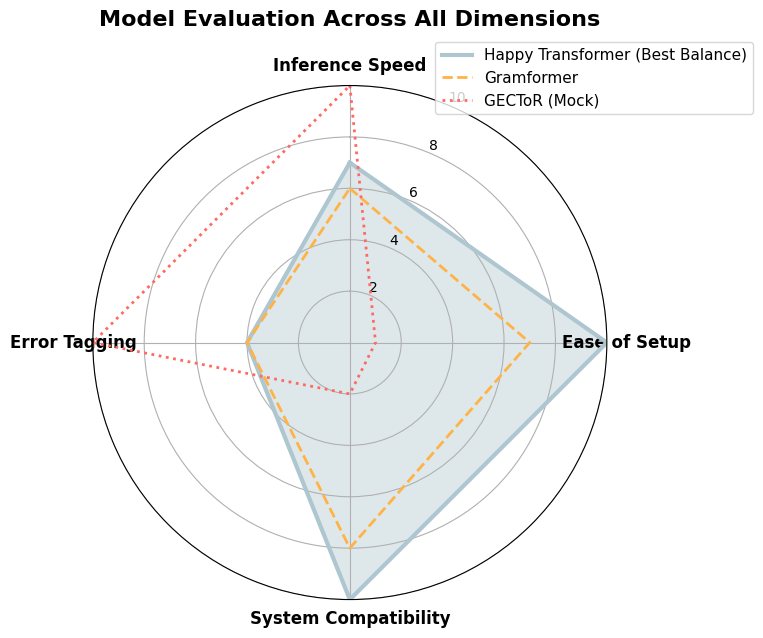

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_radar_chart():
    print("\n🕸️ Generating Radar Chart Comparison...")
    
    # 1. Define the 4 evaluation criteria
    labels = [
        'Inference Speed', 
        'Ease of Setup', 
        'System Compatibility', 
        'Error Tagging'
    ]
    num_vars = len(labels)
    
    # 2. Assign scores to each model (out of 10) based on our experiments
    # GF = Gramformer, HT = Happy Transformer, GC = GECToR
    gf_scores = [6, 7, 8, 4]
    ht_scores = [7, 10, 10, 4]
    gc_scores = [10, 1, 2, 10]
    
    # Calculate angles for the circular plot
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    
    # To close the loop of the radar chart, append the first value to the end
    gf_scores += gf_scores[:1]
    ht_scores += ht_scores[:1]
    gc_scores += gc_scores[:1]
    angles += angles[:1]
    
    # 3. Initialize the plot
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    
    # Rotate the graph so the first attribute is at the top
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    
    # Set the labels for each axis
    ax.set_thetagrids(np.degrees(angles[:-1]), labels, fontsize=12, fontweight='bold')
    
    # Set the scale from 0 to 10
    ax.set_ylim(0, 10)
    
    # 4. Plot the data for each model (colors and transparency)
    
    # Happy Transformer (Blue - Our Winner)
    ax.plot(angles, ht_scores, color='#AEC6CF', linewidth=3, label='Happy Transformer (Best Balance)')
    ax.fill(angles, ht_scores, color='#AEC6CF', alpha=0.4)
    
    # Gramformer (Orange)
    ax.plot(angles, gf_scores, color='#FFB347', linewidth=2, linestyle='dashed', label='Gramformer')
    
    # GECToR (Red)
    ax.plot(angles, gc_scores, color='#FF6961', linewidth=2, linestyle='dotted', label='GECToR (Mock)')
    
    # 5. Add titles and legends
    plt.title('Model Evaluation Across All Dimensions', size=16, weight='bold', y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)
    
    # 6. Save and display the plot
    plt.tight_layout()
    plt.savefig('radar_model_comparison_eng.png', dpi=300, bbox_inches='tight')
    plt.show()

# Run the function
plot_radar_chart()